(sec-14-1)=
# 14.1 The Discrete Wavelet Transform and Filter Banks

An ECG contains changes on several time scales: a sharp QRS complex, slower P and T waves, and baseline drift over longer intervals. Wavelets help us examine those scales separately. The discrete wavelet transform does this through repeated filtering and downsampling.

I will begin with a small Haar-transform example that we can calculate by hand, then connect it to filter banks and a real ECG. We will also reconstruct the signal, because separating it into coefficients is useful only if we understand what those coefficients retain and how to put them back together.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pywt
import wfdb
from matplotlib.patches import FancyBboxPatch, Circle
from scipy import signal

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=3, suppress=True)
rng = np.random.default_rng(42)

(sec-14-1-1)=
## 14.1.1 From the Continuous Transform to a Dyadic Grid

Recall from Section 23.3 that the continuous wavelet transform compares the signal with stretched and shifted copies of a mother wavelet $\psi(t)$:

(eq-14-1)=
\begin{equation*}
W_x(a, b) = \int_{-\infty}^{\infty} x(t)\, \frac{1}{\sqrt{a}}\, \psi^*\!\left(\frac{t - b}{a}\right) dt, \qquad a > 0. \tag{14.1}
\end{equation*}

In this expression, $x(t)$ is the signal and $\psi$ is the analyzing wavelet. The scale $a>0$ stretches or compresses the wavelet, and $b$ moves it along time. The star means complex conjugation. We multiply the signal by this shifted, scaled wavelet and integrate to measure their overlap. The discrete transform will select particular scales and positions, rather than evaluate every possible pair.

A one-dimensional signal becomes a two-dimensional function of scale $a$ and position $b$, so the CWT is highly redundant. Neighboring coefficients are strongly correlated for two reasons. A wavelet at scale $a$ lasts roughly $a$ seconds, so shifting it by a small fraction of $a$ barely changes what it sees. And two scales such as $a$ and $1.05a$ cover almost the same frequency band.

This suggests an economy. Sample the scale geometrically, one value per octave, $a = 2^j$, and sample the position in steps proportional to the scale, $b = k\,2^j$, because a wide wavelet needs fewer positions than a narrow one. Substituting both into the kernel of [(14.1)](#eq-14-1),

(eq-14-2)=
\begin{equation*}
\frac{1}{\sqrt{2^j}}\,\psi\!\left(\frac{t - k 2^j}{2^j}\right) = 2^{-j/2}\,\psi\!\left(2^{-j} t - k\right) \equiv \psi_{j,k}(t), \qquad j, k \in \mathbb{Z}. \tag{14.2}
\end{equation*}

This is the **dyadic grid**. Count the coefficients it produces. If the signal has $N$ samples, level $j = 1$ needs $N/2$ positions, level 2 needs $N/4$, and so on. After $J$ levels we also keep $N/2^J$ coarse "approximation" values that summarize what is left, and the total is

$$
\frac{N}{2} + \frac{N}{4} + \cdots + \frac{N}{2^J} + \frac{N}{2^J} = N .
$$

The dyadic transform produces exactly as many numbers as it receives. The obvious worry is that this sampling throws information away. For a generic wavelet it does. But Daubechies showed that there exist wavelets for which the functions $\psi_{j,k}$ form an **orthonormal basis** {cite:p}`daubechies1992`, and then nothing is lost: the signal is expanded on the basis exactly as a periodic signal is expanded on sinusoids, with coefficients given by inner products ([Section 2.2](../ch02_math_toolkit/03_signals_as_vectors.ipynb)).

### The multiresolution idea

The cleanest way to see how such a basis is built is Mallat's **multiresolution analysis** {cite:p}`mallat1989`. I find it easiest to think of it in terms of approximations. Let $V_j$ be the set of signals that can be described at resolution $2^j$. In the simplest (Haar) case, for sampled signals, $V_j$ contains the sequences that are constant on consecutive blocks of $2^j$ samples. These spaces are nested,

$$
V_0 \supset V_1 \supset V_2 \supset \cdots,
$$

because a signal that is constant on blocks of 8 is also constant on blocks of 4. The best approximation of $x$ in $V_j$ (its orthogonal projection) is obtained by replacing each block by its mean. Going from $V_{j-1}$ to the coarser $V_j$ loses some information, the **detail** at level $j$, and that detail lives in a space $W_j$ that is orthogonal to $V_j$:

$$
V_{j-1} = V_j \oplus W_j \quad\Longrightarrow\quad V_0 = V_J \oplus W_J \oplus W_{J-1} \oplus \cdots \oplus W_1 .
$$

The right-hand side is the DWT in one line: a signal equals a coarse approximation plus details at every intermediate scale. The approximation spaces are spanned by shifted copies of a **scaling function** $\varphi(t)$ and the detail spaces by the wavelets $\psi_{j,k}$. For Haar, $\varphi$ is the unit box on $[0, 1)$ and $\psi$ is $+1$ on the first half and $-1$ on the second. Because a box of width 1 is two boxes of width $\tfrac12$ placed side by side, both functions satisfy **two-scale equations**,

$$
\varphi(t) = \varphi(2t) + \varphi(2t - 1), \qquad \psi(t) = \varphi(2t) - \varphi(2t - 1).
$$

Every orthonormal wavelet obeys a relation of this kind, $\varphi(t) = \sqrt{2}\sum_n c[n]\,\varphi(2t - n)$, with some short sequence $c[n]$ (for Haar, $c = [1/\sqrt{2},\, 1/\sqrt{2}]$). We will see shortly that $c[n]$ is, up to a time reversal, the low-pass filter of a filter bank, and that this filter is all we need to compute the transform.

The figure shows the multiresolution idea on one heartbeat from MIT-BIH record 100 {cite:p}`moody2001,goldberger2000`. Each panel replaces blocks of $2^j$ samples by their mean. At $j = 2$ (blocks of 11 ms) the beat is essentially intact. At $j = 4$ (44 ms) the QRS complex has collapsed into a single block of less than half its height, while the P wave and the slow segments between the waves are still followed closely. At $j = 6$ (178 ms) the QRS complex has disappeared altogether and only the baseline level remains: everything faster has moved into the details.

In [2]:
fs = 360
seg = wfdb.rdrecord("../data/mitdb/100", sampfrom=0, sampto=1024).p_signal[:, 0]
t_seg = np.arange(seg.size) / fs


def haar_approximation(x, j):
    """Projection onto V_j: replace each block of 2**j samples by its mean."""
    block = 2 ** j
    return np.repeat(x.reshape(-1, block).mean(axis=1), block)


# the block means equal PyWavelets' Haar reconstruction with all details set to zero
coeffs = pywt.wavedec(seg, "haar", level=4)
coeffs = [coeffs[0]] + [np.zeros_like(d) for d in coeffs[1:]]
print("max |block mean - pywt approximation| at j = 4:",
      f"{np.max(np.abs(haar_approximation(seg, 4) - pywt.waverec(coeffs, 'haar'))):.1e} mV")

max |block mean - pywt approximation| at j = 4: 2.8e-16 mV


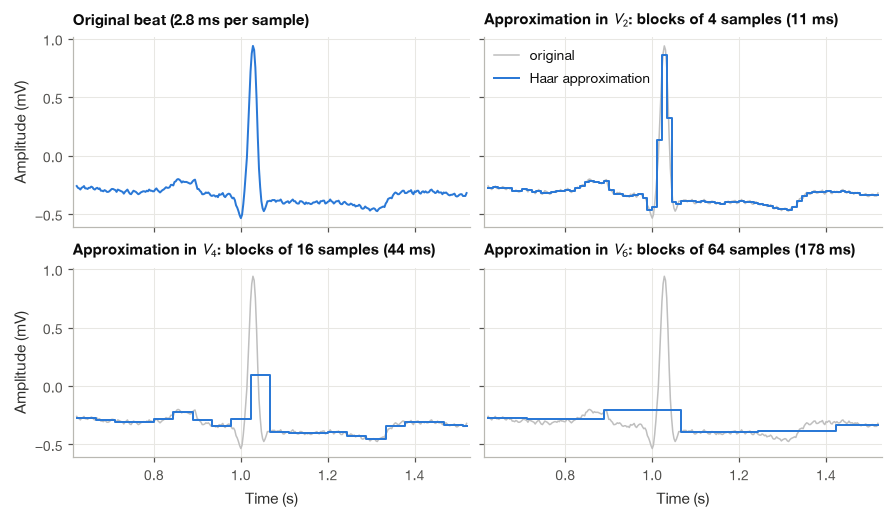

In [3]:
win = (t_seg >= 0.62) & (t_seg < 1.52)
fig, axes = plt.subplots(2, 2, figsize=(8, 4.6), sharex=True, sharey=True)
panels = [(0, "Original beat (2.8 ms per sample)")] + [
    (j, f"Approximation in $V_{j}$: blocks of {2**j} samples ({1000 * 2**j / fs:.0f} ms)") for j in (2, 4, 6)]
for ax, (j, title) in zip(axes.flat, panels):
    if j:
        ax.plot(t_seg[win], seg[win], color="0.75", lw=1, label="original")
        ax.step(t_seg[win], haar_approximation(seg, j)[win], where="post", color=C[0], lw=1.3,
                label="Haar approximation")
    else:
        ax.plot(t_seg[win], seg[win], color=C[0], lw=1.3)
    ax.set_title(title, fontsize=10)
for ax in axes[1]:
    ax.set_xlabel("Time (s)")
for ax in axes[:, 0]:
    ax.set_ylabel("Amplitude (mV)")
axes[0, 1].legend(loc="upper left")
plt.show()

(sec-14-1-2)=
## 14.1.2 The Haar Transform by Hand

Before any filter theory, we compute a complete Haar transform with pencil and paper.

**Example 14.1.1.** Compute the three-level orthonormal Haar transform of $\mathbf{x} = [4,\ 6,\ 10,\ 12,\ 8,\ 6,\ 5,\ 5]$.

**Step 1: pairwise averages and half-differences.** Group the samples in pairs, $(4, 6), (10, 12), (8, 6), (5, 5)$. For each pair compute the average and half the difference:

$$
\text{averages} = [5,\ 11,\ 7,\ 5], \qquad \text{half-differences} = [-1,\ -1,\ 1,\ 0].
$$

Nothing has been lost, because each pair can be rebuilt as (average $+$ half-difference, average $-$ half-difference); for the first pair, $5 + (-1) = 4$ and $5 - (-1) = 6$. The averages are a half-resolution copy of the signal, and the half-differences are small wherever the signal is locally flat.

**Step 2: make the step orthonormal.** Averages and half-differences shrink the numbers, so the transform does not preserve energy. Multiplying both by $\sqrt{2}$ fixes this. We define

(eq-14-3)=
\begin{equation*}
a_1[k] = \frac{x[2k] + x[2k+1]}{\sqrt{2}}, \qquad d_1[k] = \frac{x[2k] - x[2k+1]}{\sqrt{2}}. \tag{14.3}
\end{equation*}

To see that energy is preserved, expand the squares for a single pair:

$$
\begin{aligned}
a_1[k]^2 + d_1[k]^2 &= \frac{(x_0 + x_1)^2 + (x_0 - x_1)^2}{2} \\
&= \frac{x_0^2 + 2x_0x_1 + x_1^2 + x_0^2 - 2x_0x_1 + x_1^2}{2} \\
&= x_0^2 + x_1^2 ,
\end{aligned}
$$

where $x_0 = x[2k]$ and $x_1 = x[2k+1]$: the cross terms cancel. For our signal,

$$
\mathbf{a}_1 = \tfrac{1}{\sqrt{2}}[10,\ 22,\ 14,\ 10] \approx [7.071,\ 15.556,\ 9.899,\ 7.071], \qquad
\mathbf{d}_1 = \tfrac{1}{\sqrt{2}}[-2,\ -2,\ 2,\ 0] \approx [-1.414,\ -1.414,\ 1.414,\ 0].
$$

**Step 3: repeat on the approximation.** Apply [(14.3)](#eq-14-3) to $\mathbf{a}_1$. The first pair gives $(10/\sqrt{2} + 22/\sqrt{2})/\sqrt{2} = 32/2 = 16$, and so on:

$$
\mathbf{a}_2 = [16,\ 12], \qquad \mathbf{d}_2 = [-6,\ 2].
$$

**Step 4: repeat once more.** $a_3 = (16 + 12)/\sqrt{2} = 19.799$ and $d_3 = (16 - 12)/\sqrt{2} = 2.828$.

The complete transform, ordered from coarse to fine as PyWavelets returns it, is

$$
[\,a_3 \mid d_3 \mid \mathbf{d}_2 \mid \mathbf{d}_1\,] = [\,19.799 \mid 2.828 \mid -6,\ 2 \mid -1.414,\ -1.414,\ 1.414,\ 0\,].
$$

Each number has a meaning. The single approximation $a_3 = 19.799$ is $\sqrt{8}$ times the mean of the signal (which is 7). The coefficient $d_2[0] = -6$ is large because the signal climbs from about 5 to about 11 between its first and second pair, while the finest details are all small because neighboring samples are similar. The energy check works out: $\sum x^2 = 446$, and $19.799^2 + 2.828^2 + 36 + 4 + 2 + 2 + 2 + 0 = 392 + 8 + 40 + 6 = 446$.

### Matrix form

One level of [(14.3)](#eq-14-3) is a matrix multiplication. For $N = 8$, the first four rows of the matrix compute the averages and the last four the differences:

$$
\begin{bmatrix} \mathbf{a}_1 \\ \mathbf{d}_1 \end{bmatrix} = \mathbf{W}_1\mathbf{x}, \qquad
\mathbf{W}_1 = \frac{1}{\sqrt{2}}
\begin{bmatrix}
1 & 1 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 1 & 1 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 1 & 1 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 1 & 1 \\
1 & -1 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 1 & -1 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 1 & -1 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 1 & -1
\end{bmatrix}.
$$

Every row has unit length ($\tfrac12 + \tfrac12 = 1$). Two rows that touch different pairs are orthogonal because their nonzero entries never overlap, and the average row and difference row of the same pair are orthogonal because $\tfrac12 - \tfrac12 = 0$. So $\mathbf{W}_1\mathbf{W}_1^T = \mathbf{I}$, the matrix is orthogonal, and its inverse is simply its transpose. **Perfect reconstruction** is therefore automatic: $\mathbf{x} = \mathbf{W}_1^T[\mathbf{a}_1;\ \mathbf{d}_1]$. The full three-level transform is a product of three such matrices (each later one acting only on the approximation part), and a product of orthogonal matrices is orthogonal. The rows of that product are the discrete Haar basis vectors. We now check all of this numerically.

In [4]:
x8 = np.array([4, 6, 10, 12, 8, 6, 5, 5], dtype=float)


def haar_matrix_one_level(n):
    """Orthonormal one-level Haar analysis matrix for a length-n signal (equation 24.3)."""
    W = np.zeros((n, n))
    for k in range(n // 2):
        W[k, 2 * k:2 * k + 2] = [1, 1]
        W[n // 2 + k, 2 * k:2 * k + 2] = [1, -1]
    return W / np.sqrt(2)


# levels 2 and 3 act on the approximation block only, so pad them with an identity
W1 = haar_matrix_one_level(8)
W2 = np.eye(8); W2[:4, :4] = haar_matrix_one_level(4)
W3 = np.eye(8); W3[:2, :2] = haar_matrix_one_level(2)
W = W3 @ W2 @ W1

print("W x          :", W @ x8)
print("pywt.wavedec :", np.concatenate(pywt.wavedec(x8, "haar", level=3)))
print(f"W W^T = I    : {np.allclose(W @ W.T, np.eye(8))}")
print(f"energy       : {np.sum(x8**2):.1f} (signal)  {np.sum((W @ x8)**2):.1f} (coefficients)")
print(f"W^T (W x) = x: {np.allclose(W.T @ (W @ x8), x8)}")
print("rows of sqrt(8) W (the discrete Haar basis):")
print(np.sqrt(8) * W)

W x          : [19.799  2.828 -6.     2.    -1.414 -1.414  1.414  0.   ]
pywt.wavedec : [19.799  2.828 -6.     2.    -1.414 -1.414  1.414  0.   ]
W W^T = I    : True
energy       : 446.0 (signal)  446.0 (coefficients)
W^T (W x) = x: True
rows of sqrt(8) W (the discrete Haar basis):
[[ 1.     1.     1.     1.     1.     1.     1.     1.   ]
 [ 1.     1.     1.     1.    -1.    -1.    -1.    -1.   ]
 [ 1.414  1.414 -1.414 -1.414  0.     0.     0.     0.   ]
 [ 0.     0.     0.     0.     1.414  1.414 -1.414 -1.414]
 [ 2.    -2.     0.     0.     0.     0.     0.     0.   ]
 [ 0.     0.     2.    -2.     0.     0.     0.     0.   ]
 [ 0.     0.     0.     0.     2.    -2.     0.     0.   ]
 [ 0.     0.     0.     0.     0.     0.     2.    -2.   ]]


The first row of $\sqrt{8}\,\mathbf{W}$ is constant (the mean), the second is a single slow square wave, and the lower rows are shorter and shorter "up-down" patterns at different positions: discrete Haar wavelets at three scales.

(sec-14-1-3)=
## 14.1.3 The Two-Channel Filter Bank

Equation [(14.3)](#eq-14-3) can be read as filtering. Convolve $x$ with the two-tap filters $h_0 = [\tfrac{1}{\sqrt2}, \tfrac{1}{\sqrt2}]$ and $h_1 = [-\tfrac{1}{\sqrt2}, \tfrac{1}{\sqrt2}]$, and keep every second output: $(x * h_0)[2k+1] = (x[2k+1] + x[2k])/\sqrt2 = a_1[k]$ and $(x * h_1)[2k+1] = (x[2k] - x[2k+1])/\sqrt2 = d_1[k]$. The first filter is a moving average, a crude low-pass; the second is a first difference, a crude high-pass ([Section 13.3](../ch13_filter_fundamentals/index.md)). Keeping every second sample is **downsampling by two**, written $\downarrow 2$. (Whether we keep the even or the odd outputs only changes the overall delay; in the analysis below we keep the even ones.) The inverse runs the other way: insert zeros between the coefficients (**upsampling**, $\uparrow 2$), filter with synthesis filters $f_0$ and $f_1$, and add the two branches. The structure is called a **two-channel filter bank**.

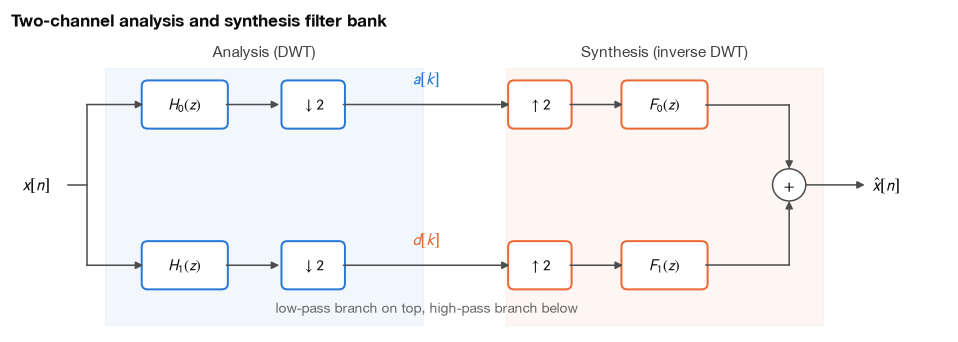

In [5]:
fig, ax = plt.subplots(figsize=(8.6, 3.0))
ax.set(xlim=(0, 12.4), ylim=(0.2, 4.2), title="Two-channel analysis and synthesis filter bank")
ax.axis("off")


def block(xc, yc, text, w=1.1, h=0.62, color=C[0]):
    ax.add_patch(FancyBboxPatch((xc - w / 2, yc - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc="white", ec=color, lw=1.3))
    ax.text(xc, yc, text, ha="center", va="center", fontsize=10)


def arrow(x0, y0, x1, y1):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle="-|>", color="0.3", lw=1.0, shrinkA=0, shrinkB=0))


ax.axvspan(1.25, 5.45, ymin=0.02, ymax=0.9, color=C[0], alpha=0.06)
ax.axvspan(6.55, 10.75, ymin=0.02, ymax=0.9, color=C[1], alpha=0.06)
ax.text(3.35, 3.95, "Analysis (DWT)", ha="center", fontsize=10, color="0.25")
ax.text(8.65, 3.95, "Synthesis (inverse DWT)", ha="center", fontsize=10, color="0.25")
ax.text(0.15, 2.2, "$x[n]$", ha="left", va="center", fontsize=11)
ax.plot([0.75, 1.0], [2.2, 2.2], color="0.3", lw=1.0)
ax.plot([1.0, 1.0], [1.1, 3.3], color="0.3", lw=1.0)
for y, h, f, c, color in [(3.3, "$H_0(z)$", "$F_0(z)$", "$a[k]$", C[0]), (1.1, "$H_1(z)$", "$F_1(z)$", "$d[k]$", C[1])]:
    arrow(1.0, y, 1.75, y)
    block(2.3, y, h)
    arrow(2.85, y, 3.55, y)
    block(4.0, y, r"$\downarrow 2$", w=0.8)
    arrow(4.4, y, 6.6, y)
    ax.text(5.5, y + 0.22, c, ha="center", va="bottom", fontsize=11, color=color)
    block(7.0, y, r"$\uparrow 2$", w=0.8, color=C[1])
    arrow(7.4, y, 8.1, y)
    block(8.65, y, f, color=C[1])
    ax.plot([9.2, 10.3], [y, y], color="0.3", lw=1.0)
ax.add_patch(Circle((10.3, 2.2), 0.22, fc="white", ec="0.3", lw=1.0))
ax.text(10.3, 2.2, "+", ha="center", va="center", fontsize=12)
arrow(10.3, 3.3, 10.3, 2.42)
arrow(10.3, 1.1, 10.3, 1.98)
arrow(10.52, 2.2, 11.3, 2.2)
ax.text(11.4, 2.2, r"$\hat{x}[n]$", ha="left", va="center", fontsize=11)
ax.text(5.5, 0.45, "low-pass branch on top, high-pass branch below", ha="center", fontsize=9, color="0.4")
plt.show()

For Haar we already know that the synthesis side undoes the analysis side. The question for any other pair of filters is: under what conditions is $\hat{x}[n]$ an exact (possibly delayed) copy of $x[n]$? We answer it in the $z$-domain.

**Step 1: what downsampling followed by upsampling does.** Let $v[n]$ be a branch signal just before $\downarrow 2$. Downsampling and then upsampling keeps the even-indexed samples and replaces the odd ones by zeros. Since $\tfrac12\big(1 + (-1)^n\big)$ equals 1 for even $n$ and 0 for odd $n$, the result is

$$
w[n] = \tfrac12\big(1 + (-1)^n\big)\, v[n] .
$$

Taking the $z$-transform term by term, and noting that $\sum_n (-1)^n v[n] z^{-n} = \sum_n v[n] (-z)^{-n} = V(-z)$,

(eq-14-4)=
\begin{equation*}
W(z) = \tfrac12\big[V(z) + V(-z)\big]. \tag{14.4}
\end{equation*}

On the unit circle, $-z = -e^{j\Omega} = e^{j(\Omega + \pi)}$, so $V(-z)$ is the spectrum shifted by half the sampling rate. That shifted copy is **aliasing**, the price of throwing samples away ([Section 6.2](../ch09_sampling/index.md)).

**Step 2: follow both branches.** In the low-pass branch $V(z) = H_0(z)X(z)$; after [(14.4)](#eq-14-4) and the synthesis filter $F_0(z)$ it contributes $\tfrac12 F_0(z)\big[H_0(z)X(z) + H_0(-z)X(-z)\big]$. The high-pass branch is identical with the subscript 1. Adding the two and grouping terms by $X(z)$ and $X(-z)$,

(eq-14-5)=
\begin{equation*}
\hat{X}(z) = \underbrace{\tfrac12\big[F_0(z)H_0(z) + F_1(z)H_1(z)\big]}_{T(z)\ \text{(distortion)}}\, X(z)
\;+\; \underbrace{\tfrac12\big[F_0(z)H_0(-z) + F_1(z)H_1(-z)\big]}_{A(z)\ \text{(aliasing)}}\, X(-z). \tag{14.5}
\end{equation*}

**Step 3: read off the conditions.** The output is a delayed copy of the input, $\hat{x}[n] = x[n - \ell]$, exactly when

(eq-14-6)=
\begin{equation*}
\begin{aligned}
&\text{alias cancellation:} && F_0(z)H_0(-z) + F_1(z)H_1(-z) = 0, \\
&\text{no distortion:} && F_0(z)H_0(z) + F_1(z)H_1(z) = 2z^{-\ell}.
\end{aligned} \tag{14.6}
\end{equation*}

Aliasing need not be avoided in each branch; it only has to cancel between them. The first condition is satisfied by choosing the synthesis filters as

$$
F_0(z) = -H_1(-z), \qquad F_1(z) = H_0(-z),
$$

because then $F_0(z)H_0(-z) + F_1(z)H_1(-z) = -H_1(-z)H_0(-z) + H_0(-z)H_1(-z) = 0$ identically. With this choice the whole design problem collapses onto the second condition.

**Example 14.1.2.** Verify [(14.6)](#eq-14-6) for Haar. Here $H_0(z) = (1 + z^{-1})/\sqrt2$ and $H_1(z) = (-1 + z^{-1})/\sqrt2$. Replacing $z$ by $-z$ flips the sign of $z^{-1}$, so $F_0(z) = -H_1(-z) = (1 + z^{-1})/\sqrt2$ and $F_1(z) = H_0(-z) = (1 - z^{-1})/\sqrt2$. Then

$$
\begin{aligned}
F_0(z)H_0(z) + F_1(z)H_1(z) &= \tfrac12(1 + z^{-1})^2 + \tfrac12(1 - z^{-1})(-1 + z^{-1}) \\
&= \tfrac12\big(1 + 2z^{-1} + z^{-2}\big) - \tfrac12\big(1 - 2z^{-1} + z^{-2}\big) \\
&= 2z^{-1}.
\end{aligned}
$$

So $\ell = 1$: the Haar filter bank returns its input delayed by one sample.

### Orthonormal filter banks

For an orthonormal wavelet the four filters are tied even more tightly. All of them derive from a single low-pass filter $h_0$ of even length $L$: the analysis high-pass is its **alternating flip**, and the synthesis filters are time-reversed analysis filters,

(eq-14-7)=
\begin{equation*}
h_1[n] = (-1)^{n+1}\, h_0[L - 1 - n], \qquad f_0[n] = h_0[L-1-n], \qquad f_1[n] = h_1[L-1-n]. \tag{14.7}
\end{equation*}

The time reversal is the filter-bank version of "the inverse of an orthogonal matrix is its transpose". These filters also satisfy the **power-complementary** property $|H_0(e^{j\Omega})|^2 + |H_1(e^{j\Omega})|^2 = 2$: whatever energy the low-pass rejects at a given frequency, the high-pass keeps. PyWavelets stores the four filters of every wavelet as `dec_lo`, `dec_hi`, `rec_lo`, `rec_hi` {cite:p}`lee2019`. We verify [(14.6)](#eq-14-6) and [(14.7)](#eq-14-7) for the 8-tap Daubechies filter `db4`, which we meet properly in the next subsection, by multiplying polynomials (convolving coefficient sequences), and then run an actual signal through the bank.

In [6]:
w = pywt.Wavelet("db4")
h0, h1, f0, f1 = (np.array(f) for f in w.filter_bank)       # dec_lo, dec_hi, rec_lo, rec_hi
L = h0.size
alt = (-1.0) ** np.arange(L)                                  # coefficients of H(-z) are (-1)^n h[n]

distortion = np.convolve(f0, h0) + np.convolve(f1, h1)       # 2 T(z), equation (24.5)
alias = np.convolve(f0, alt * h0) + np.convolve(f1, alt * h1)  # 2 A(z)
print("F0 H0 + F1 H1 coefficients:", np.round(distortion, 12))
print(f"max |alias term|          : {np.max(np.abs(alias)):.1e}")
print(f"alternating flip (24.7)   : {np.allclose(h1, -alt * h0[::-1])}")
print(f"time-reversed synthesis   : {np.allclose(f0, h0[::-1]) and np.allclose(f1, h1[::-1])}")

Om, H0 = signal.freqz(h0, worN=1024)
_, H1 = signal.freqz(h1, worN=1024)
print(f"|H0|^2 + |H1|^2 ranges from {np.min(abs(H0)**2 + abs(H1)**2):.6f} "
      f"to {np.max(abs(H0)**2 + abs(H1)**2):.6f}")

# run a random signal through the bank: filter, keep even samples, upsample, filter, add
x = rng.normal(size=200)
branches = []
for h, f in [(h0, f0), (h1, f1)]:
    v = np.convolve(x, h)[::2]
    up = np.zeros(2 * v.size); up[::2] = v
    branches.append(np.convolve(up, f))
x_hat = branches[0] + branches[1]
ell = L - 1
print(f"output = input delayed by {ell} samples: {np.allclose(x_hat[ell:ell + x.size], x)}")

F0 H0 + F1 H1 coefficients: [ 0. -0. -0. -0. -0.  0.  0.  2.  0.  0.  0. -0. -0. -0.  0.]
max |alias term|          : 2.8e-17
alternating flip (24.7)   : True
time-reversed synthesis   : True
|H0|^2 + |H1|^2 ranges from 2.000000 to 2.000000
output = input delayed by 7 samples: True


The distortion polynomial is $2z^{-7}$, the alias polynomial vanishes to machine precision, and a random signal comes back delayed by $\ell = L - 1 = 7$ samples, exactly as the theory predicts.

(sec-14-1-4)=
## 14.1.4 Daubechies Wavelets and Vanishing Moments

The Haar filter bank is perfect in the algebraic sense, but as a pair of filters it is poor. Its low-pass response is $|H_0(e^{j\Omega})| = \sqrt{2}\,|\cos(\Omega/2)|$, which falls off so gently that the "half-band" split leaks heavily between the two channels. Its basis functions are also discontinuous, so a smooth signal such as a T wave or a slow baseline drift generates many nonzero detail coefficients. Daubechies asked for the shortest orthonormal filters that are blind to smooth signals {cite:p}`daubechies1992`.

### Vanishing moments

A wavelet has $p$ **vanishing moments** if $\int t^m \psi(t)\,dt = 0$ for $m = 0, 1, \ldots, p - 1$. The discrete counterpart is a statement about the high-pass filter:

(eq-14-8)=
\begin{equation*}
\sum_n n^m\, h_1[n] = 0, \qquad m = 0, 1, \ldots, p - 1. \tag{14.8}
\end{equation*}

Why does this make the filter blind to polynomials? Feed it the monomial $x[n] = n^m$ with $m < p$ and expand $(n - k)^m$ with the binomial theorem:

$$
\begin{aligned}
(x * h_1)[n] &= \sum_k h_1[k]\,(n - k)^m \\
&= \sum_k h_1[k] \sum_{i=0}^{m} \binom{m}{i} n^{m-i} (-k)^i \\
&= \sum_{i=0}^{m} \binom{m}{i} n^{m-i} (-1)^i \underbrace{\sum_k k^i\, h_1[k]}_{=\,0 \text{ by (24.8), since } i \le m < p} = 0 .
\end{aligned}
$$

By linearity, every polynomial of degree less than $p$ produces zero output. In the frequency domain the same property says that $H_1(e^{j\Omega})$ has a zero of order $p$ at $\Omega = 0$, or equivalently that $H_0(z)$ has $p$ zeros at $z = -1$ (the Nyquist frequency). Daubechies' construction factors the low-pass filter as $H_0(z) = \big(\tfrac{1 + z^{-1}}{2}\big)^p Q(z)$ and chooses the shortest $Q(z)$ that keeps the bank orthonormal; the result has $2p$ taps. In PyWavelets the name `dbp` means $p$ vanishing moments, so `db1` is Haar and `db4` has 4 vanishing moments and 8 taps. (Some texts name the same filter "D8" after its length, so it pays to check the length before comparing results across papers.)

We check [(14.8)](#eq-14-8) and the polynomial blindness directly. The table below reports, for each filter, the largest high-pass output relative to the input when the input is a polynomial of degree 0 to 4 (we keep only the "valid" part of the convolution, so the signal edges play no role).

In [7]:
n = np.arange(256)
u = (n - 128) / 32                         # a well-scaled time axis for the test polynomials
rows = {}
for p in range(1, 5):
    g = np.array(pywt.Wavelet(f"db{p}").dec_hi)
    rows[f"db{p} ({g.size} taps)"] = [np.max(np.abs(np.convolve(u**m, g, "valid"))) / np.max(np.abs(u**m))
                                      for m in range(5)]
table = pd.DataFrame(rows, index=[f"degree {m}" for m in range(5)]).T
print("max |high-pass output| / max |input| for polynomial inputs")
print(table.to_string(float_format="%.1e"))

max |high-pass output| / max |input| for polynomial inputs
              degree 0  degree 1  degree 2  degree 3  degree 4
db1 (2 taps)   0.0e+00   5.5e-03   1.1e-02   1.6e-02   2.2e-02
db2 (4 taps)   5.6e-17   7.9e-17   7.5e-05   2.2e-04   4.4e-04
db3 (6 taps)   0.0e+00   6.4e-17   5.4e-17   1.6e-06   6.2e-06
db4 (8 taps)   0.0e+00   6.9e-17   5.8e-17   4.6e-17   4.7e-08


The staircase of values near $10^{-17}$ (machine precision) shows exactly the pattern of the derivation: `db1` only annihilates constants, `db2` also kills straight lines, and `db4` kills everything up to cubics. For the ECG this means that the slowly curving segments between waves, and most of a gentle baseline drift, leave the fine-scale `db4` detail coefficients almost untouched, so the energy of those coefficients concentrates on the sharp QRS complex.

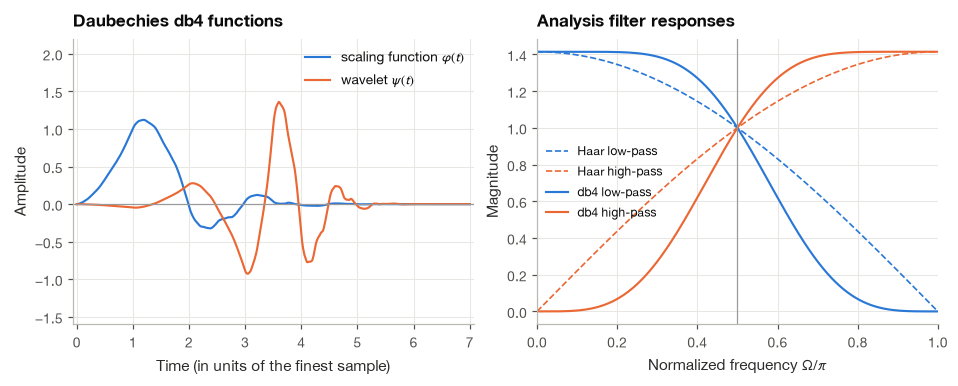

In [8]:
phi, psi, t_w = pywt.Wavelet("db4").wavefun(level=10)
_, H0_haar = signal.freqz(pywt.Wavelet("haar").dec_lo, worN=1024)
_, H1_haar = signal.freqz(pywt.Wavelet("haar").dec_hi, worN=1024)

fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.4))
ax = axes[0]
ax.plot(t_w, phi, color=C[0], label=r"scaling function $\varphi(t)$")
ax.plot(t_w, psi, color=C[1], label=r"wavelet $\psi(t)$")
ax.axhline(0, color="0.6", lw=0.8)
ax.set(xlabel="Time (in units of the finest sample)", ylabel="Amplitude",
       title="Daubechies db4 functions", ylim=(-1.6, 2.2))
ax.legend(loc="upper right")

ax = axes[1]
ax.plot(Om / np.pi, np.abs(H0_haar), color=C[0], ls="--", lw=1.1, label="Haar low-pass")
ax.plot(Om / np.pi, np.abs(H1_haar), color=C[1], ls="--", lw=1.1, label="Haar high-pass")
ax.plot(Om / np.pi, np.abs(H0), color=C[0], label="db4 low-pass")
ax.plot(Om / np.pi, np.abs(H1), color=C[1], label="db4 high-pass")
ax.axvline(0.5, color="0.6", lw=0.8)
ax.set(xlabel=r"Normalized frequency $\Omega/\pi$", ylabel="Magnitude", xlim=(0, 1),
       title="Analysis filter responses")
ax.legend(loc="center left", fontsize=8)
plt.show()

The db4 functions are asymmetric and somewhat irregular (Daubechies wavelets cannot be both orthonormal and symmetric, except for Haar), but they are continuous and localized. Their filters split the band at $\Omega = \pi/2$ much more sharply than Haar's, with flat responses near $\Omega = 0$ and $\Omega = \pi$, the flatness that the vanishing moments buy.

(sec-14-1-5)=
## 14.1.5 Mallat's Algorithm: The Multilevel DWT

One stage of the filter bank splits the signal into a half-band approximation and a half-band detail. **Mallat's algorithm** {cite:p}`mallat1989` simply repeats the split on the approximation:

1. Set $a_0[n] = x[n]$.
2. For $j = 1, \ldots, J$: compute $a_j = (a_{j-1} * h_0)\!\downarrow\!2$ and $d_j = (a_{j-1} * h_1)\!\downarrow\!2$.
3. Return $[a_J, d_J, d_{J-1}, \ldots, d_1]$.

The inverse runs the same tree backwards with the synthesis filters. The cost is remarkable. The first stage filters $N$ samples with two filters of length $L$, about $LN$ multiplications after downsampling. The second stage works on $N/2$ samples and costs half as much, and so on, so the total is below $LN(1 + \tfrac12 + \tfrac14 + \cdots) = 2LN$. The DWT is $O(N)$, cheaper even than the FFT.

We implement it twice from scratch. The Haar version follows [(14.3)](#eq-14-3) directly. The general version works for any orthonormal filter pair and treats the signal as periodic, so every stage maps $N$ samples to exactly $N/2 + N/2$ coefficients; its inverse is the transpose of the analysis operator, which is all an orthonormal transform needs.

In [9]:
def haar_dwt(x, level):
    """Multilevel orthonormal Haar DWT (24.3); returns [a_J, d_J, ..., d_1] like pywt.wavedec."""
    a, details = np.asarray(x, dtype=float), []
    for _ in range(level):
        a, d = (a[0::2] + a[1::2]) / np.sqrt(2), (a[0::2] - a[1::2]) / np.sqrt(2)
        details.insert(0, d)
    return [a] + details


def haar_idwt(coeffs):
    """Inverse of haar_dwt: rebuild each pair from (a + d)/sqrt(2) and (a - d)/sqrt(2)."""
    a = coeffs[0]
    for d in coeffs[1:]:
        x = np.empty(2 * a.size)
        x[0::2], x[1::2] = (a + d) / np.sqrt(2), (a - d) / np.sqrt(2)
        a = x
    return a


def _periodic_index(n_out, L, N):
    """Indices 2k + L/2 - m (mod N) of the input samples that meet tap m at output k."""
    return (2 * np.arange(n_out)[:, None] + L // 2 - np.arange(L)[None, :]) % N


def dwt(x, h0, h1, level):
    """Mallat's algorithm with periodic extension for an orthonormal filter pair."""
    a, details = np.asarray(x, dtype=float), []
    for _ in range(level):
        idx = _periodic_index(a.size // 2, h0.size, a.size)
        a, d = a[idx] @ h0, a[idx] @ h1
        details.insert(0, d)
    return [a] + details


def idwt(coeffs, h0, h1):
    """Inverse of dwt: apply the transpose of each analysis stage, coarse to fine."""
    a = coeffs[0]
    for d in coeffs[1:]:
        N = 2 * a.size
        idx = _periodic_index(a.size, h0.size, N)
        x = np.zeros(N)
        np.add.at(x, idx, a[:, None] * h0[None, :] + d[:, None] * h1[None, :])
        a = x
    return a


x = rng.normal(size=1024)
ref = pywt.wavedec(x, "haar", level=6)
mine = haar_dwt(x, 6)
print(f"Haar, from scratch vs pywt   : max diff {max(np.max(np.abs(m - r)) for m, r in zip(mine, ref)):.1e}, "
      f"reconstruction error {np.max(np.abs(haar_idwt(mine) - x)):.1e}")

ref = pywt.wavedec(x, "db4", level=6, mode="periodization")
mine = dwt(x, h0, h1, 6)
print(f"db4, from scratch vs pywt    : max diff {max(np.max(np.abs(m - r)) for m, r in zip(mine, ref)):.1e}, "
      f"reconstruction error {np.max(np.abs(idwt(mine, h0, h1) - x)):.1e}")
print("coefficients per level       :", [c.size for c in mine], "total", sum(c.size for c in mine))
print(f"energy (signal, coefficients): {np.sum(x**2):.4f}, {sum(np.sum(c**2) for c in mine):.4f}")

Haar, from scratch vs pywt   : max diff 2.7e-15, reconstruction error 1.3e-15
db4, from scratch vs pywt    : max diff 8.9e-16, reconstruction error 1.3e-15
coefficients per level       : [16, 16, 32, 64, 128, 256, 512] total 1024
energy (signal, coefficients): 1044.4265, 1044.4265


Both implementations agree with PyWavelets to machine precision, reconstruct their input, preserve energy, and return exactly 1024 numbers for 1024 samples.

(sec-14-1-6)=
## 14.1.6 Which Frequencies Does Each Level Hold?

To interpret DWT coefficients physiologically we need the frequency band of each level. The argument is a short induction on the sampling rate.

**Level 1.** The input is sampled at $f_s$ and contains frequencies in $[0, f_s/2]$. The half-band filters split this range at $f_s/4$: $h_1$ keeps $[f_s/4, f_s/2]$ and $h_0$ keeps $[0, f_s/4]$. After downsampling, both branches are sampled at $f_s/2$, whose Nyquist frequency $f_s/4$ is exactly the width of each half band, so (ideally) nothing overlaps.

**Level $j$.** The approximation entering level $j$ has been downsampled $j - 1$ times. Its sampling rate is $f_s/2^{j-1}$ and its content occupies $[0, f_s/2^j]$. The high-pass takes the upper half of that range.

Hence

(eq-14-9)=
\begin{equation*}
d_j \;\leftrightarrow\; \left[\frac{f_s}{2^{j+1}},\ \frac{f_s}{2^{j}}\right], \qquad a_J \;\leftrightarrow\; \left[0,\ \frac{f_s}{2^{J+1}}\right]. \tag{14.9}
\end{equation*}

The bands are octaves: each is half as wide as the one above it, just as the CWT's constant-Q analysis suggested. There is one subtlety. Downsampling the high-pass branch folds its band $[f_s/4, f_s/2]$ down onto $[0, f_s/4]$ in mirrored order, so a detail coefficient sequence should not be read as an ordinary low-frequency signal. It is a compact code for what happened in its band.

For the MIT-BIH sampling rate of 360 Hz, equation [(14.9)](#eq-14-9) gives the following table. The right column anticipates what we will find on real data.

| Level | Band (Hz) | Main ECG content at 360 Hz |
|---|---|---|
| $d_1$ | 90–180 | mostly noise (EMG, quantization) |
| $d_2$ | 45–90 | sharp QRS edges, power-line interference at 50/60 Hz |
| $d_3$ | 22.5–45 | QRS complex |
| $d_4$ | 11.25–22.5 | QRS complex (most energy) |
| $d_5$ | 5.6–11.25 | QRS complex, P and T waves |
| $d_6$ | 2.8–5.6 | P and T waves |
| $d_7$ | 1.4–2.8 | P and T waves, heart-rate fundamental region |
| $d_8$ | 0.70–1.4 | T wave, slow components |
| $a_8$ | 0–0.70 | baseline wander, respiration effects |

Real filters are not brick walls, so the bands in [(14.9)](#eq-14-9) are approximate. We can measure how approximate. Thanks to the **noble identity** (filtering with $H(z)$ after $\downarrow 2$ is the same as filtering with $H(z^2)$ before it), the cascade that produces $d_j$ collapses into one equivalent filter followed by downsampling by $2^j$:

(eq-14-10)=
\begin{equation*}
H^{(j)}_{\text{eq}}(z) = H_1\!\left(z^{2^{j-1}}\right) \prod_{i=0}^{j-2} H_0\!\left(z^{2^i}\right). \tag{14.10}
\end{equation*}

Replacing $z$ by $z^{2^i}$ in the time domain means inserting $2^i - 1$ zeros between filter taps, so the equivalent filter is a convolution of upsampled copies of $h_0$ and $h_1$.

In [10]:
def upsample_filter(h, factor):
    """Coefficients of H(z**factor): insert factor - 1 zeros between taps."""
    out = np.zeros((h.size - 1) * factor + 1)
    out[::factor] = h
    return out


def equivalent_filters(h0, h1, level):
    """Equivalent detail filters for levels 1..level and the final approximation filter (24.10)."""
    lowpass, details = np.array([1.0]), []
    for j in range(1, level + 1):
        details.append(np.convolve(lowpass, upsample_filter(h1, 2 ** (j - 1))))
        lowpass = np.convolve(lowpass, upsample_filter(h0, 2 ** (j - 1)))
    return details, lowpass


J = 8
eq_details, eq_approx = equivalent_filters(h0, h1, J)
f_grid = np.linspace(0, fs / 2, 2**15)
rows = []
for j, g in enumerate(eq_details + [eq_approx], start=1):
    _, G = signal.freqz(g, worN=f_grid, fs=fs)
    power = np.abs(G) ** 2
    lo, hi = (fs / 2 ** (j + 1), fs / 2**j) if j <= J else (0, fs / 2 ** (J + 1))
    inside = (f_grid >= lo) & (f_grid <= hi)
    rows.append([f"d{j}" if j <= J else f"a{J}", g.size, f"{lo:.2f}-{hi:.2f}",
                 100 * power[inside].sum() / power.sum()])
bands = pd.DataFrame(rows, columns=["level", "taps", "nominal band (Hz)", "% of energy in band"])
print(bands.to_string(index=False, float_format="%.1f"))

level  taps nominal band (Hz)  % of energy in band
   d1     8      90.00-180.00                 90.9
   d2    22       45.00-90.00                 73.3
   d3    50       22.50-45.00                 73.1
   d4   106       11.25-22.50                 73.1
   d5   218        5.62-11.25                 73.1
   d6   442         2.81-5.62                 73.1
   d7   890         1.41-2.81                 73.1
   d8  1786         0.70-1.41                 73.1
   a8  1786         0.00-0.70                 90.7


About three quarters of the energy of each detail filter from $d_2$ to $d_8$ falls inside its nominal octave, and about 91 percent for $d_1$ and $a_8$, which have a neighbor on one side only. Equation [(14.9)](#eq-14-9) is therefore a useful guide, but neighboring levels overlap considerably, and a component exactly at a band edge shows up in both levels. The equivalent filters also grow long: the level-8 filter has more than 1700 taps (almost 5 s at 360 Hz), which is why the coarse levels see slow phenomena.

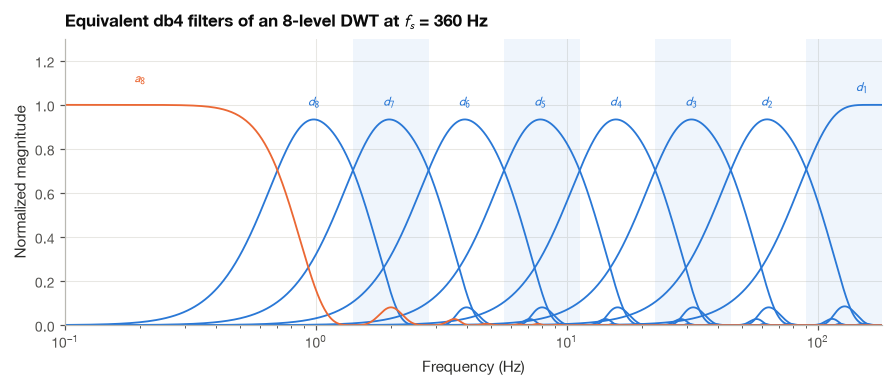

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.4))
for j, g in enumerate(eq_details, start=1):
    _, G = signal.freqz(g, worN=f_grid[1:], fs=fs)
    gain = np.abs(G) / 2 ** (j / 2)                      # the level-j filter has passband gain 2^(j/2)
    ax.plot(f_grid[1:], gain, color=C[0], lw=1.2)
    k = np.argmax(gain)
    ax.text(min(f_grid[1:][k], 150), gain[k] + 0.06, f"$d_{j}$", ha="center", fontsize=9, color=C[0])
    if j % 2:
        ax.axvspan(fs / 2 ** (j + 1), fs / 2**j, color=C[0], alpha=0.07, lw=0)
_, G = signal.freqz(eq_approx, worN=f_grid[1:], fs=fs)
ax.plot(f_grid[1:], np.abs(G) / 2 ** (J / 2), color=C[1], lw=1.2)
ax.text(0.2, 1.1, "$a_8$", color=C[1], fontsize=9, ha="center")
ax.set_xscale("log")
ax.set(xlim=(0.1, 180), ylim=(0, 1.3), xlabel="Frequency (Hz)", ylabel="Normalized magnitude",
       title="Equivalent db4 filters of an 8-level DWT at $f_s$ = 360 Hz")
plt.show()

(sec-14-1-7)=
## 14.1.7 Taking a Real ECG Apart

We now apply the transform to the ECG. I use the first $2^{15} = 32{,}768$ samples (91 s) of MIT-BIH record 100, lead MLII, a clean recording at about 74 beats per minute. A power-of-two length lets us use periodic extension without padding, which keeps the transform exactly orthonormal so that energies add up exactly.

### Step 1: Load the record and remove the offset

The recording has a constant offset of about $-0.33$ mV that comes from the amplifier, not the heart. Left in place it would dominate the approximation energy, so we subtract the mean.

In [12]:
N = 2**15
rec = wfdb.rdrecord("../data/mitdb/100", sampto=N)
ecg_raw = rec.p_signal[:, 0]
ecg = ecg_raw - ecg_raw.mean()
t = np.arange(N) / fs
ann = wfdb.rdann("../data/mitdb/100", "atr", sampto=N)
r_peaks = ann.sample[np.isin(ann.symbol, ["N", "A", "V"])]
print(f"{rec.sig_name[0]} lead, {N} samples ({N / fs:.1f} s), {r_peaks.size} beats, "
      f"offset removed: {ecg_raw.mean():.3f} mV")

MLII lead, 32768 samples (91.0 s), 112 beats, offset removed: -0.327 mV


### Step 2: Decompose into eight levels

Eight levels at 360 Hz bring the approximation down to the 0 to 0.7 Hz band of baseline wander. We use `db4`, a common choice for ECG because its 4 vanishing moments ignore the smooth segments while its short support (8 taps) keeps the QRS complex compact.

In [13]:
coeffs = pywt.wavedec(ecg, "db4", level=J, mode="periodization")
names = [f"a{J}"] + [f"d{J - i}" for i in range(J)]
print("coefficients per level:", dict(zip(names, [c.size for c in coeffs])))

coefficients per level: {'a8': 128, 'd8': 128, 'd7': 256, 'd6': 512, 'd5': 1024, 'd4': 2048, 'd3': 4096, 'd2': 8192, 'd1': 16384}


### Step 3: Look at the coefficients

To place each coefficient on the time axis we need the delay of each level's equivalent filter. Rather than computing it analytically, we push a unit impulse through the transform and take the centre of gravity of each level's response. The figure shows the coefficients over three seconds, one stem per coefficient, so the halving of the number of coefficients from level to level is visible directly.

In [14]:
def level_delays(level, wavelet="db4", n=N):
    """Sample offset that aligns coefficient k of each level with time 2**j * k + delay."""
    impulse = np.zeros(n); impulse[n // 2] = 1.0
    c = pywt.wavedec(impulse, wavelet, level=level, mode="periodization")
    delays = []
    for i, ci in enumerate(c):
        j = level if i == 0 else level - i + 1
        k, e = np.arange(ci.size), ci**2
        delays.append(n // 2 - 2**j * np.sum(k * e) / e.sum())
    return delays


delays = level_delays(J)

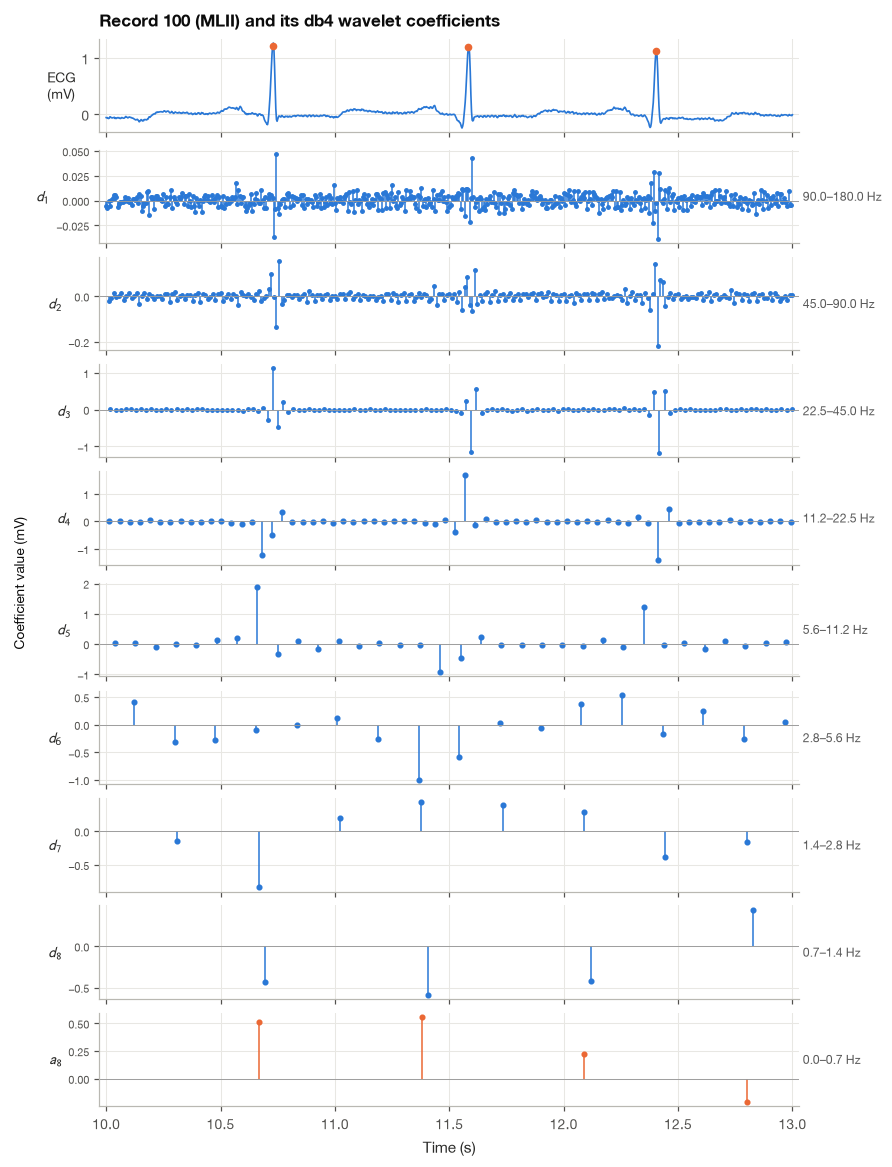

In [15]:
t0, t1 = 10.0, 13.0
order = list(range(J, 0, -1)) + [0]                       # d1 (finest) at the top, a8 at the bottom
fig, axes = plt.subplots(len(order) + 1, 1, figsize=(8, 10.5), sharex=True)
sel = (t >= t0) & (t <= t1)
axes[0].plot(t[sel], ecg[sel], color=C[0], lw=1.1)
axes[0].plot(r_peaks[(r_peaks / fs >= t0) & (r_peaks / fs <= t1)] / fs,
             ecg[r_peaks[(r_peaks / fs >= t0) & (r_peaks / fs <= t1)]], "o", color=C[1], ms=4)
axes[0].set_title("Record 100 (MLII) and its db4 wavelet coefficients", fontsize=11)
axes[0].set_ylabel("ECG\n(mV)", rotation=0, ha="right", va="center", fontsize=9)
for ax, i in zip(axes[1:], order):
    j = J if i == 0 else J - i + 1
    tc = (2**j * np.arange(coeffs[i].size) + delays[i]) / fs
    keep = (tc >= t0) & (tc <= t1)
    color = C[1] if i == 0 else C[0]
    ax.vlines(tc[keep], 0, coeffs[i][keep], color=color, lw=1.0)
    ax.plot(tc[keep], coeffs[i][keep], "o", color=color, ms=2.2 if j <= 3 else 3)
    ax.axhline(0, color="0.6", lw=0.6)
    lo, hi = (fs / 2 ** (j + 1), fs / 2**j) if i else (0, fs / 2 ** (J + 1))
    label = f"$a_{j}$" if i == 0 else f"$d_{j}$"
    ax.set_ylabel(label, rotation=0, ha="right", va="center", fontsize=10)
    ax.text(1.005, 0.5, f"{lo:.1f}–{hi:.1f} Hz", transform=ax.transAxes, fontsize=8, va="center", color="0.35")
    ax.tick_params(axis="y", labelsize=7)
axes[-1].set_xlabel("Time (s)")
fig.supylabel("Coefficient value (mV)", fontsize=9)
plt.show()

Each coefficient summarizes a stretch of $2^j$ samples, so its position is only meaningful to within about one coefficient spacing (89 ms at $d_5$, 0.7 s at $d_8$). With that in mind, the picture matches the table of Section 14.1.6. The finest level $d_1$ contains only low-level noise. Levels $d_3$ and $d_4$ respond sharply and only at the QRS complexes, $d_5$ responds to the QRS complex and the waves around it, and levels $d_6$ to $d_8$ follow the P and T waves. The approximation $a_8$ moves slowly with the baseline.

### Step 4: Measure the energy per level

Because the transform is orthonormal, the energy of the coefficients at each level is that level's exact share of the signal energy. To connect levels with waves, we also rebuild each level as a time-domain signal (all other coefficients set to zero) and split its energy between samples within $\pm 60$ ms of an R peak, which contain the QRS complex, and all other samples, which contain the P wave, the T wave and the baseline.

In [16]:
qrs_mask = np.zeros(N, dtype=bool)
half = int(0.060 * fs)
for r in r_peaks:
    qrs_mask[max(r - half, 0):r + half] = True

rows = []
for i, name in enumerate(names):
    only = [np.zeros_like(c) for c in coeffs]
    only[i] = coeffs[i]
    part = pywt.waverec(only, "db4", mode="periodization")
    rows.append([name, np.sum(coeffs[i] ** 2), np.sum(part[qrs_mask] ** 2), np.sum(part[~qrs_mask] ** 2)])
energy = pd.DataFrame(rows, columns=["level", "E", "E_qrs", "E_rest"]).set_index("level")
energy = 100 * energy / energy.sum()
energy.columns = ["% of total energy", "% of QRS-window energy", "% of energy elsewhere"]
print(f"QRS windows cover {100 * qrs_mask.mean():.1f}% of the samples")
print(energy.iloc[::-1].round(1).to_string())

QRS windows cover 14.4% of the samples
       % of total energy  % of QRS-window energy  % of energy elsewhere
level                                                                  
d1                   0.1                     0.1                    0.2
d2                   1.5                     1.8                    0.5
d3                  16.6                    22.1                    0.5
d4                  34.9                    44.5                    7.0
d5                  23.6                    23.9                   22.8
d6                   8.8                     4.6                   21.3
d7                   4.4                     1.4                   13.3
d8                   3.5                     0.4                   12.8
a8                   6.5                     1.3                   21.7


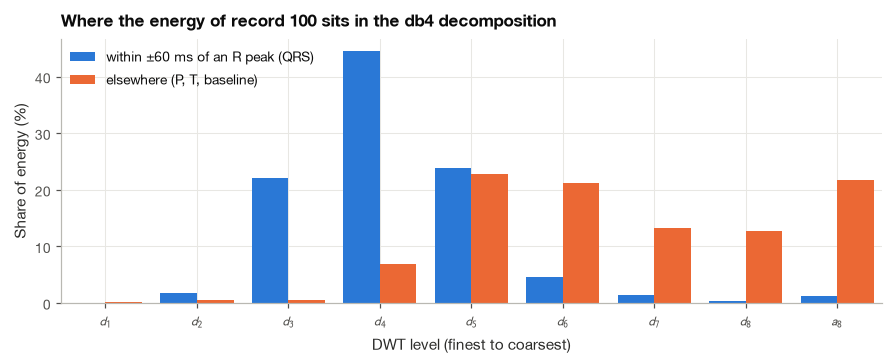

In [17]:
lev = energy.index[::-1]
xpos = np.arange(lev.size)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(xpos - 0.2, energy["% of QRS-window energy"].values[::-1], width=0.4, color=C[0],
       label="within ±60 ms of an R peak (QRS)")
ax.bar(xpos + 0.2, energy["% of energy elsewhere"].values[::-1], width=0.4, color=C[1],
       label="elsewhere (P, T, baseline)")
ax.set_xticks(xpos, [f"${s[0]}_{s[1:]}$" for s in lev])
ax.set(xlabel="DWT level (finest to coarsest)", ylabel="Share of energy (%)",
       title="Where the energy of record 100 sits in the db4 decomposition")
ax.legend(loc="upper left")
plt.show()

The QRS complex is concentrated in three levels: $d_3$, $d_4$ and $d_5$ hold about 90 percent of the energy inside the QRS windows, with $d_4$ (11 to 22 Hz) alone holding close to half. Outside the QRS complex the energy spreads over $d_5$ to $d_8$ and $a_8$, the territory of the P and T waves and the baseline. This is the reason many wavelet-based QRS detectors work on $d_3$ to $d_5$ only (compare the 5 to 15 Hz band-pass of the Pan–Tompkins detector in Section 19.1), and why wavelet features at these levels are useful for beat classification in Section 27.1.

### Step 5: Remove baseline wander by zeroing the approximation

Record 100 has very little baseline wander, so to make the problem visible we add the real baseline-wander recording `bw` from the MIT-BIH Noise Stress Test Database {cite:p}`moody1984`, which was captured from electrodes placed on an active volunteer where the ECG is barely visible. Its RMS value is about 0.4 mV, and 90 percent of its power lies below about 0.23 Hz. Since the wander sits in the approximation band, we remove it by setting $a_8$ to zero and inverting the transform. Because the result is linear in the input, the corrected signal is the corrected clean ECG plus the part of the wander that survives the operation, and we can measure that residual directly. We also try $a_9$ (0 to 0.35 Hz).

In [18]:
bw = wfdb.rdrecord("../data/nstdb/bw", sampto=N).p_signal[:, 0]
noisy = ecg + bw


def remove_approximation(x, level, wavelet="db4"):
    """Zero the coarsest approximation of a DWT and reconstruct (baseline removal)."""
    c = pywt.wavedec(x, wavelet, level=level)
    c[0] = np.zeros_like(c[0])
    return pywt.waverec(c, wavelet)[:x.size]


rms = lambda v: np.sqrt(np.mean(v**2))
f_bw, P_bw = signal.welch(bw - bw.mean(), fs, nperseg=40 * fs)
f90 = f_bw[np.searchsorted(np.cumsum(P_bw) / P_bw.sum(), 0.9)]
print(f"baseline wander alone              : RMS {rms(bw):.3f} mV, 90% of its power below {f90:.2f} Hz")
for level in (8, 9):
    residual = remove_approximation(bw, level)
    change = remove_approximation(ecg, level) - ecg
    print(f"zero a{level} (0-{fs / 2**(level + 1):.2f} Hz): residual wander RMS {rms(residual):.3f} mV, "
          f"change to the clean ECG RMS {rms(change):.3f} mV")
corrected = remove_approximation(noisy, 8)
baseline_est = noisy - corrected

baseline wander alone              : RMS 0.412 mV, 90% of its power below 0.23 Hz
zero a8 (0-0.70 Hz): residual wander RMS 0.050 mV, change to the clean ECG RMS 0.045 mV
zero a9 (0-0.35 Hz): residual wander RMS 0.099 mV, change to the clean ECG RMS 0.044 mV


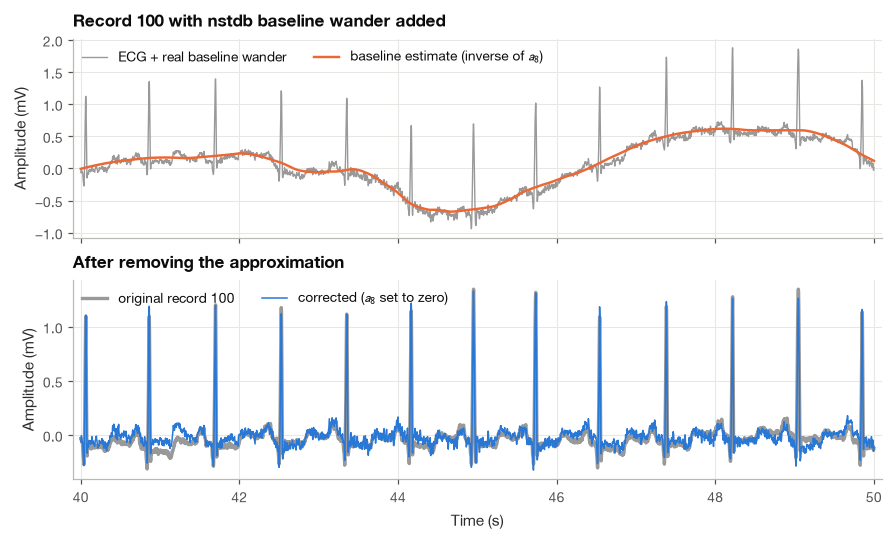

In [19]:
sel = (t >= 40) & (t <= 50)
fig, axes = plt.subplots(2, 1, figsize=(8, 4.8), sharex=True)
axes[0].plot(t[sel], noisy[sel], color="0.6", lw=0.9, label="ECG + real baseline wander")
axes[0].plot(t[sel], baseline_est[sel], color=C[1], lw=1.6, label="baseline estimate (inverse of $a_8$)")
axes[0].set(ylabel="Amplitude (mV)", title="Record 100 with nstdb baseline wander added")
axes[0].legend(loc="upper left", ncols=2)
axes[1].plot(t[sel], ecg[sel], color="0.6", lw=2.2, label="original record 100")
axes[1].plot(t[sel], corrected[sel], color=C[0], lw=1.0, label="corrected ($a_8$ set to zero)")
axes[1].set(xlabel="Time (s)", ylabel="Amplitude (mV)", title="After removing the approximation")
axes[1].legend(loc="upper left", ncols=2)
plt.show()

Zeroing $a_8$ cuts the wander from 0.41 mV to about 0.05 mV RMS while changing the clean ECG by a similar small amount; zeroing $a_9$ disturbs the ECG equally little but leaves twice as much wander behind, because the `bw` recording has some power between 0.35 and 0.7 Hz. The choice of level is a choice of cutoff frequency, with the same trade-off as for the high-pass filters of [Section 12.2](../ch18_ecg_preprocessing/index.md): a higher cutoff removes more wander but distorts more of the low-frequency ECG content, in particular the ST segment, which matters for ischemia monitoring. The wavelet version has one practical advantage: the cutoff adapts automatically to the record length and sampling rate through [(14.9)](#eq-14-9), and the same decomposition can be reused for denoising ([Section 14.2](02_wavelet_denoising.ipynb)) and feature extraction.

(sec-14-1-8)=
## 14.1.8 What Happens at the Edges

Real signals have ends, and every filter in the bank needs samples beyond them. The DWT must therefore **extend** the signal at each edge, and the choice of extension changes both the number of coefficients and the artifacts near the edges. PyWavelets offers several modes {cite:p}`lee2019`. With `periodization` the signal is treated as periodic, each level has exactly half as many coefficients as its input, and the transform stays orthonormal; the cost is an artificial jump wherever the end of the signal does not match its beginning. The default `symmetric` mode mirrors the signal at each edge, which avoids jumps but produces a few extra coefficients per level ($\lfloor (N + L - 1)/2 \rfloor$ instead of $N/2$), so the transform is no longer exactly orthonormal. Modes such as `zero` (pad with zeros) and `smooth` (extrapolate linearly) sit in between.

The vanishing moments make the effect easy to see. A pure ramp, like a linear baseline drift, produces exactly zero `db4` detail coefficients away from the edges, so any nonzero $d_1$ coefficient comes from the edge treatment alone.

In [20]:
ramp = 0.5 + 0.002 * np.arange(1024)               # a linear drift from 0.5 to 2.5 mV
rows = []
for mode in ["periodization", "symmetric", "zero", "smooth"]:
    c = pywt.wavedec(ramp, "db4", level=3, mode=mode)
    d1 = c[-1]
    rows.append([mode, sum(ci.size for ci in c), np.max(np.abs(np.r_[d1[:4], d1[-4:]])), np.max(np.abs(d1[8:-8]))])
print(pd.DataFrame(rows, columns=["mode", "total coefficients", "max |d1| at the edges",
                                  "max |d1| inside"]).to_string(index=False, float_format="%.2e"))

         mode  total coefficients  max |d1| at the edges  max |d1| inside
periodization                1024               4.72e-01         4.58e-16
    symmetric                1044               1.29e-04         4.09e-16
         zero                1044               1.23e+00         4.09e-16
       smooth                1044               2.88e-16         4.09e-16


Inside the signal every mode gives zero, as the vanishing moments promise. At the edges, `periodization` sees a jump from 2.5 mV back to 0.5 mV and produces large coefficients, `zero` sees two jumps to zero, `symmetric` sees only a kink, and `smooth` continues the line and produces no edge coefficients at all. For an ECG segment that starts and ends at different baseline levels, I use `symmetric` (or discard a few hundred milliseconds at each end) unless exact orthonormality is needed, as it was for the energy table in Step 4.

## Summary

The discrete wavelet transform samples the continuous transform on the dyadic grid $a = 2^j$, $b = k2^j$. With an orthonormal wavelet nothing is lost, and the transform returns exactly $N$ coefficients for $N$ samples. Computationally it is a two-channel filter bank: a low-pass $h_0$ and a high-pass $h_1$, each followed by downsampling, applied repeatedly to the low-pass branch (Mallat's algorithm), at a total cost of $O(N)$. Downsampling creates aliasing, but the alias terms cancel between the two branches when the synthesis filters are chosen as in [(14.6)](#eq-14-6), and orthonormal banks satisfy the remaining no-distortion condition with filters derived from a single low-pass by alternating flip and time reversal. Daubechies filters add vanishing moments, which make the high-pass branch blind to polynomials and concentrate the energy of smooth signals in the approximation. Level $j$ covers roughly the octave $[f_s/2^{j+1}, f_s/2^j]$; at 360 Hz the QRS complex lives in $d_3$ to $d_5$, the P and T waves in $d_5$ to $d_8$, and the baseline wander in $a_8$, which can be removed by zeroing it.

These properties are the foundation of the next section, where the sparsity of the ECG in the wavelet domain lets us separate it from noise by thresholding coefficients ([Section 14.2](02_wavelet_denoising.ipynb)), and of the wavelet features we feed to beat classifiers in Chapter 27.

## Exercises

1. Compute by hand the three-level Haar transform of $\mathbf{x} = [2,\ 2,\ 4,\ 8,\ 6,\ 6,\ 0,\ 2]$, check that the energy is preserved, and verify your answer with `pywt.wavedec`. Which coefficient is largest in magnitude, and what feature of the signal does it describe?
2. Show that the downsampler is linear but not time-invariant: compare the output for $x[n]$ and for $x[n - 1]$. Then use [(14.4)](#eq-14-4) to explain in one sentence why a DWT of a shifted signal is not a shifted DWT.
3. Starting from $H_1(z) = z^{-(L-1)} H_0(-z^{-1})$, which is the $z$-domain form of the alternating flip in [(14.7)](#eq-14-7), show that $|H_1(e^{j\Omega})| = |H_0(e^{j(\Omega + \pi)})|$, so the high-pass is the low-pass mirrored about $\Omega = \pi/2$. Verify numerically for `db4`.
4. Compute the moments $\sum_n n^m h_1[n]$ for $m = 0, \ldots, 6$ for `sym4`, `coif2` and `db6`. How many vanishing moments does each have? Compare with the `vanishing_moments_psi` attribute of `pywt.Wavelet`.
5. For record 119 (360 Hz), compute the share of energy per level of an 8-level `db4` decomposition separately for windows around normal beats and around ventricular beats (`V` annotations). Which levels change most, and how does this relate to the wider QRS complex of a ventricular beat?
6. Extend `dwt` and `idwt` to `symmetric` extension and compare with `pywt.wavedec(..., mode="symmetric")` for an arbitrary signal length. (Hint: extend each approximation by $L - 1$ mirrored samples on both sides before filtering, and work out which outputs to keep.)

## Further Reading

{cite:t}`mallat1989` introduced multiresolution analysis and the fast filter-bank algorithm, and {cite:t}`daubechies1992` constructed the compactly supported orthonormal wavelets used in this section and remains the reference for their mathematics. {cite:t}`strang2016` treats the Haar transform as a change of basis in linear algebra, a viewpoint that pairs well with the matrix form in Section 14.1.2. {cite:t}`lee2019` describes PyWavelets, including its extension modes, and {cite:t}`addison2005` reviews the use of wavelet transforms on the ECG, from QRS detection to denoising and compression.